In [20]:
from pathlib import Path
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import uproot

BASE     = Path(".")                                  
CC_FILES = [BASE / "nu_cc_big" / "part_0000_hits.root"]


In [21]:
NC_FILES = [BASE / "nu_nc_big" / "part_0000_hits.root"]
f  = uproot.open(CC_FILES[0])
TR = f["PhotonTracks"]
tr = pd.DataFrame(TR.arrays(["eventID", "trackID", "parentID", "detected", "energy"], library="np"))
tr["particle"] = TR["particle"].array(library="np").astype(str)
tr["creator"]  = TR["creator"].array(library="np").astype(str)
steps = TR.arrays(["x", "y", "z", "t"], library="np")          # step points per track, mm / ns
ev = pd.DataFrame(f["Events"].arrays(["eventID", "primaryEnergy", "vx", "vy", "vz"], library="np")).set_index("eventID")
pp = pd.read_csv(CC_FILES[0].parent / "part_0000_profile_params.csv").set_index("eventID")
print(TR.num_entries, "tracks in", tr.eventID.nunique(), "events")
tr.particle.value_counts().head(8)

626413 tracks in 200 events


particle
e-               249701
opticalphoton    162786
gamma            148752
e+                36969
proton            11678
neutron            6358
alpha              1715
O16                1110
Name: count, dtype: int64

In [10]:
CHARGED = {"e-", "e+", "mu-", "mu+", "pi+", "pi-", "proton", "anti_proton", "kaon+", "kaon-", "alpha"}
EID = 18                         
v   = ev.loc[EID, ["vx", "vy", "vz"]].to_numpy(float)
idx = np.flatnonzero(tr.eventID.to_numpy() == EID)
P   = lambda i: np.stack([steps[c][i] for c in "xyz"], 1) / 1000.0   # mm -> m

mid, w = [], []
for i in idx:
    if tr.particle.iat[i] in CHARGED and len(steps["x"][i]) > 1:
        p = P(i); mid.append(0.5 * (p[1:] + p[:-1])); w.append(np.linalg.norm(np.diff(p, axis=0), axis=1))
mid, w = np.concatenate(mid), np.concatenate(w)

ph    = [i for i in idx if tr.particle.iat[i] == "opticalphoton" and tr.detected.iat[i] == 1]
emit  = np.array([P(i)[0] for i in ph])                         # where the detected light was emitted
t_det = np.array([steps["t"][i][-1] for i in ph])               # when it was detected

r = mid - v                                                     # shower axis through the vertex
u = np.linalg.eigh((r * w[:, None]).T @ r)[1][:, -1]
u = u if (r @ u * w).sum() > 0 else -u
s_trk, s_emit = r @ u, (emit - v) @ u
print(f"event {EID}: E = {ev.loc[EID,'primaryEnergy']:.1f} GeV, {w.sum():.0f} m charged track, {len(ph)} detected photons")

event 18: E = 16.2 GeV, 84 m charged track, 81 detected photons


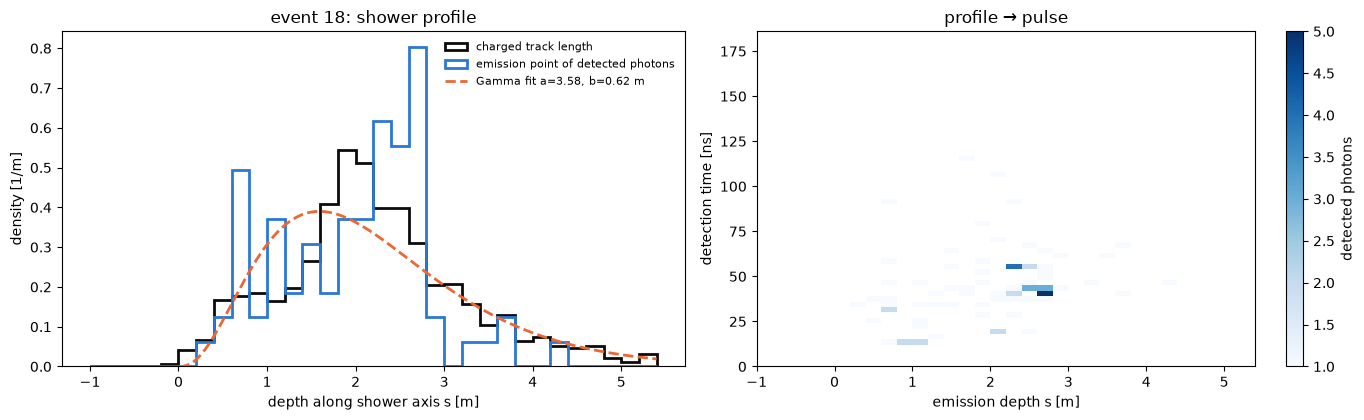

In [11]:
from scipy.special import gammaln
g = lambda s, a, b: np.exp((a - 1) * np.log(s) - s / b - gammaln(a) - a * np.log(b))

bins = np.arange(-1, np.percentile(s_trk, 99.5) + 0.2, 0.2)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
ax[0].hist(s_trk,  bins, weights=w, density=True, histtype="step", lw=2, color="#0b0b0b", label="charged track length")
ax[0].hist(s_emit, bins, density=True, histtype="step", lw=2, color="#2a78d6", label="emission point of detected photons")
if EID in pp.index:
    a, b = pp.loc[EID, ["a_mle", "b_mle"]]; ss = np.linspace(0.01, bins[-1], 300)
    ax[0].plot(ss, g(ss, a, b), "--", lw=2, color="#eb6834", label=f"Gamma fit a={a:.2f}, b={b:.2f} m")
ax[0].set(xlabel="depth along shower axis s [m]", ylabel="density [1/m]", title=f"event {EID}: shower profile")
ax[0].legend(frameon=False, fontsize=8)

h = ax[1].hist2d(s_emit, t_det, bins=[bins, np.arange(0, np.percentile(t_det, 99) + 3, 3)], cmap="Blues", cmin=1)
fig.colorbar(h[3], ax=ax[1], label="detected photons")
ax[1].set(xlabel="emission depth s [m]", ylabel="detection time [ns]", title="profile → pulse")
plt.tight_layout()

/var/folders/pc/q4bhmx_d05g82fqs1q_hnkbr0000gn/T/ipykernel_75241/1998444898.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False); ax.grid(alpha=0.25, lw=0.5)


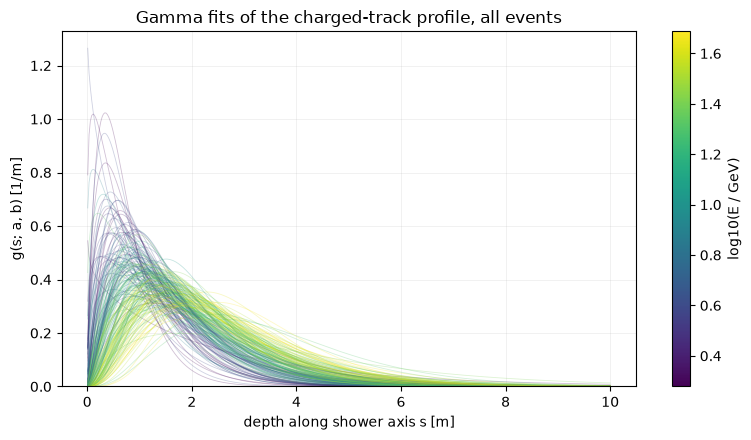

In [12]:
ss = np.linspace(0.01, 10, 400)
cmap, norm = plt.cm.viridis, plt.Normalize(np.log10(pp.E_vis_gev.min()), np.log10(pp.E_vis_gev.max()))

fig, ax = plt.subplots(figsize=(8, 4.5))
curves = []
for _, r in pp.iterrows():
    y = g(ss, r.a_mle, r.b_mle); curves.append(y)
    ax.plot(ss, y, lw=0.6, alpha=0.25, color=cmap(norm(np.log10(r.E_vis_gev))))
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label="log10(E / GeV)")
ax.set(xlabel="depth along shower axis s [m]", ylabel="g(s; a, b) [1/m]", ylim=(0, None),
       title="Gamma fits of the charged-track profile, all events")
ax.legend(frameon=False); ax.grid(alpha=0.25, lw=0.5)
plt.tight_layout()

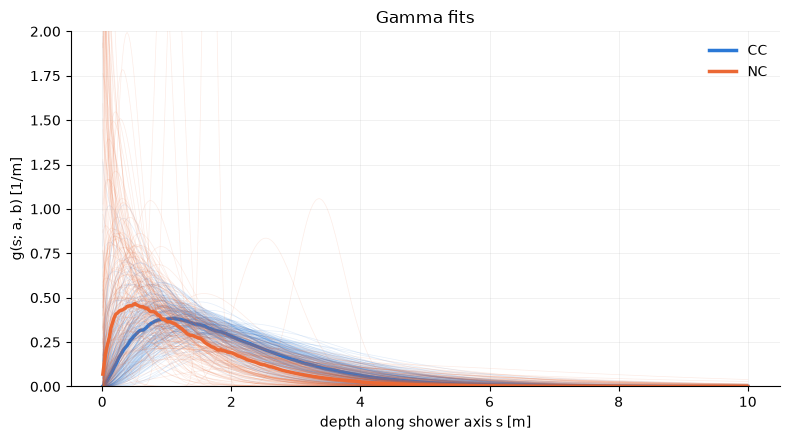

In [13]:
PP = {"CC": pd.read_csv(BASE / "nu_cc_big" / "part_0000_profile_params.csv"),
      "NC": pd.read_csv(BASE / "nu_nc_big" / "part_0000_profile_params.csv")}
COLORS = {"CC": "#2a78d6", "NC": "#eb6834"}
ss = np.linspace(0.01, 10, 400)

fig, ax = plt.subplots(figsize=(8, 4.5))
for c, d in PP.items():
    Y = np.array([g(ss, a, b) for a, b in zip(d.a_mle, d.b_mle)])
    ax.plot(ss, Y.T, lw=0.5, alpha=0.12, color=COLORS[c])
    ax.plot(ss, np.median(Y, 0), lw=2.5, color=COLORS[c],
            label=f"{c}")
ax.set(xlabel="depth along shower axis s [m]", ylabel="g(s; a, b) [1/m]", ylim=(0, None),
       title="Gamma fits")
ax.legend(frameon=False); ax.grid(alpha=0.25, lw=0.5)
ax.set_ylim(0,2)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout()

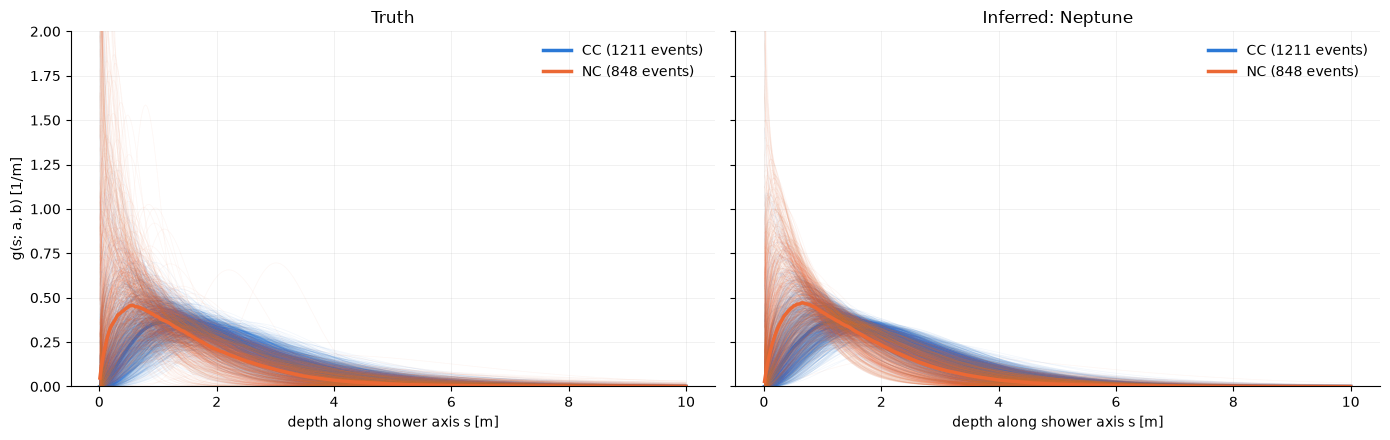

In [15]:

d   = np.load(BASE / "pulse_regressor_neptune_val.npz")               
cls = np.array(["NC" if "nc" in c else "CC" for c in d["cls"].astype(str)])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for j, (title, par) in enumerate([("Truth", d["y"]),
                                  ("Inferred: Neptune", d["mu"])]):
    for c in ("CC", "NC"):
        Y = np.array([g(ss, np.exp(la), np.exp(lb)) for la, lb in par[cls == c]])
        ax[j].plot(ss, Y.T, lw=0.5, alpha=0.06, color=COLORS[c])
        ax[j].plot(ss, np.median(Y, 0), lw=2.5, color=COLORS[c], label=f"{c} ({(cls == c).sum()} events)")
    ax[j].set(xlabel="depth along shower axis s [m]", title=title, ylim=(0, 2))
    ax[j].legend(frameon=False); ax[j].grid(alpha=0.25, lw=0.5)
    for s in ("top", "right"): ax[j].spines[s].set_visible(False)
ax[0].set_ylabel("g(s; a, b) [1/m]")
plt.tight_layout()


/var/folders/pc/q4bhmx_d05g82fqs1q_hnkbr0000gn/T/ipykernel_75241/3470431737.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False); ax.grid(alpha=0.25, lw=0.5)


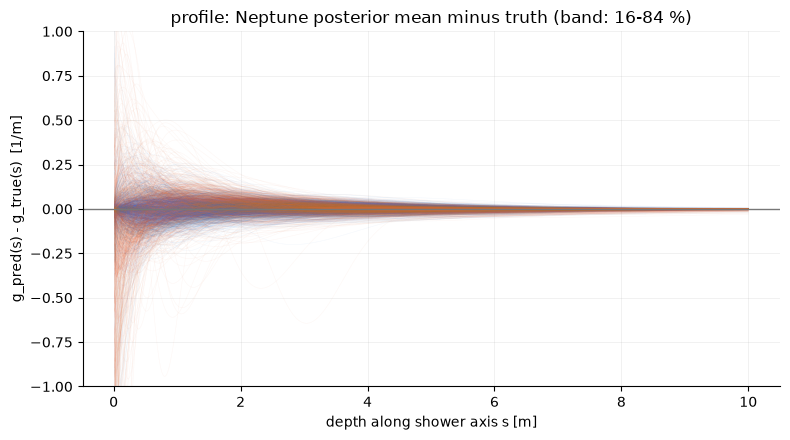

In [33]:

fig, ax = plt.subplots(figsize=(8, 4.5))
for c in ("CC", "NC"):
    m = cls == c
    dG = np.array([g(ss, *np.exp(mu)) - g(ss, *np.exp(y)) for mu, y in zip(d["mu"][m], d["y"][m])])
    q16, q50, q84 = np.percentile(dG, [16, 50, 84], axis=0)
    ax.plot(ss, dG.T, lw=0.4, alpha=0.05, color=COLORS[c])
    ax.fill_between(ss, q16, q84, color=COLORS[c], alpha=0.15, lw=0)
ax.axhline(0, color="#777", lw=1)
ax.set(xlabel="depth along shower axis s [m]", ylabel="g_pred(s) - g_true(s)  [1/m]", ylim=(-1, 1))
ax.legend(frameon=False); ax.grid(alpha=0.25, lw=0.5)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout()
